c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.
13:31:21 - cmdstanpy - INFO - Chain [1] start processing
13:31:23 - cmdstanpy - INFO - Chain [1] done processing


                     Parkings  day_of_year  weekday  hour  is_holiday
Time                                                                 
2021-10-11 00:00:00         1          284        1     0           0
2021-10-11 00:15:00         1          284        1     0           0
2021-10-11 00:30:00         1          284        1     0           0
2021-10-11 00:45:00         1          284        1     0           0
2021-10-11 01:00:00         1          284        1     1           0
...                       ...          ...      ...   ...         ...
2021-12-31 22:45:00        79          365        5    22           0
2021-12-31 23:00:00        79          365        5    23           0
2021-12-31 23:15:00        79          365        5    23           0
2021-12-31 23:30:00        77          365        5    23           0
2021-12-31 23:45:00        79          365        5    23           0

[7872 rows x 5 columns]
                     Parkings  day_of_year  weekday  hour  is_hol

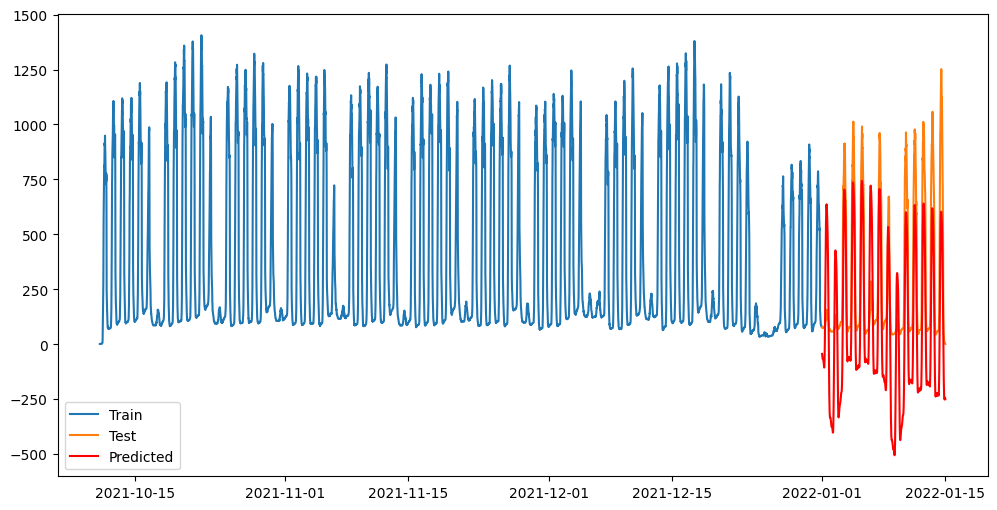

Prophet MAE: 262.07697975587666, RMSE: 290.0724551445758


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Load the dataset
df = pd.read_csv('../preprocess/parking_time_series_with_features_15min.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)

# Split the data into training and test sets
end_date = pd.to_datetime('2022-01-01')
train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]

# Prepare the data for Prophet
train_prophet = train_data.reset_index().rename(columns={'Time': 'ds', 'Parkings': 'y'})

# Initialize and fit the Prophet model
prophet_model = Prophet()
prophet_model.fit(train_prophet)

# Create a DataFrame to hold future dates for which we want predictions
future = prophet_model.make_future_dataframe(periods=len(test_data), freq='15min')

# Make predictions
prophet_forecast = prophet_model.predict(future)

# Extract the forecast for the test period
prophet_pred = prophet_forecast.set_index('ds')['yhat'][-len(test_data):]

# Print the training, test data, and predictions
print(train_data)
print(test_data)
print(prophet_pred)

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, prophet_pred, label='Predicted', color='red')
plt.legend()
plt.show()

# Calculate error metrics
mae_prophet = mean_absolute_error(test_data['Parkings'], prophet_pred)
rmse_prophet = np.sqrt(mean_squared_error(test_data['Parkings'], prophet_pred))

print(f'Prophet MAE: {mae_prophet}, RMSE: {rmse_prophet}')


15:42:45 - cmdstanpy - INFO - Chain [1] start processing
15:42:46 - cmdstanpy - INFO - Chain [1] done processing


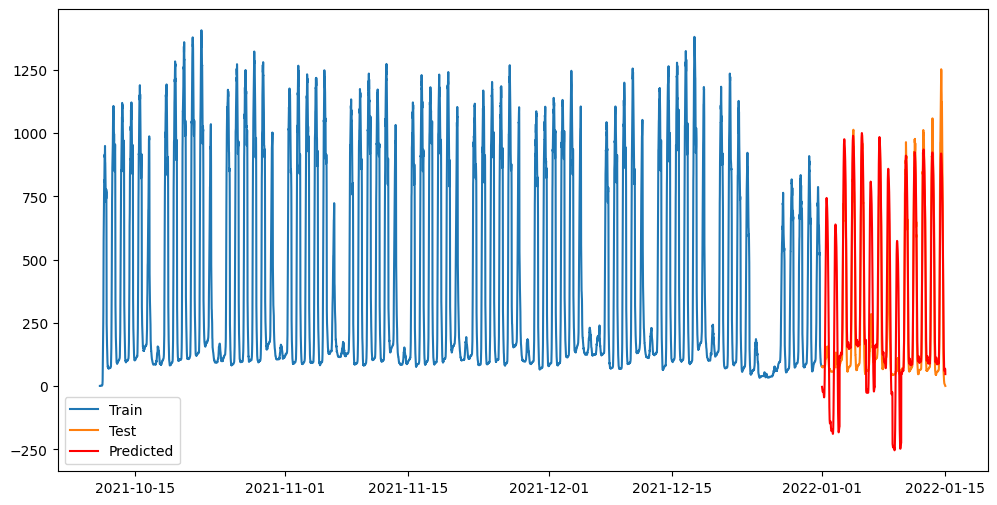

Prophet MAE: 130.35595627550742, RMSE: 187.95547078701944


In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Load the dataset
df = pd.read_csv('../preprocess/parking_time_series_with_features_15min.csv', delimiter=',')

# Parse the 'Time' column to datetime and set it as index
df['Time'] = pd.to_datetime(df['Time'])
df.set_index('Time', inplace=True)
df.sort_index(inplace=True)

# Add exogenous features
df['day_of_year'] = df.index.dayofyear
df['weekday'] = df.index.weekday
df['hour'] = df.index.hour

# Filter dates where is_holiday is 1
holidays_df = df[df['is_holiday'] == 1]

# Extract the dates
holiday_dates = holidays_df.index

holidays_df = pd.DataFrame({
  'holiday': 'finnishholidays',
  'ds': pd.to_datetime(holiday_dates),
})

# Split the data into training and test sets
end_date = pd.to_datetime('2022-01-01')
train_data = df[df.index < end_date]
test_data = df[df.index >= end_date]


# Prepare the data for Prophet
train_prophet = train_data.reset_index().rename(columns={'Time': 'ds', 'Parkings': 'y'})
test_prophet = test_data.reset_index().rename(columns={'Time': 'ds', 'Parkings': 'y'})


# Initialize and fit the Prophet model
prophet_model = Prophet(
    holidays=holidays_df, 
    weekly_seasonality=True,
    daily_seasonality=True,
    seasonality_prior_scale=0.2, 
    changepoint_prior_scale=0.015, 
    n_changepoints=15)

# Add exogenous features to the model
exogenous_features = ["day_of_year", "weekday", "hour"]
for feature in exogenous_features:
    prophet_model.add_regressor(feature)

    
prophet_model.fit(train_prophet)

# Create a DataFrame to hold future dates for which we want predictions
future = prophet_model.make_future_dataframe(periods=len(test_data), freq='15min')

# Make predictions
prophet_forecast = prophet_model.predict(test_prophet)

# Extract the forecast for the test period
prophet_pred = prophet_forecast.set_index('ds')['yhat'][-len(test_data):]

# Plot the actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(train_data.index, train_data['Parkings'], label='Train')
plt.plot(test_data.index, test_data['Parkings'], label='Test')
plt.plot(test_data.index, prophet_pred, label='Predicted', color='red')
plt.legend()
plt.show()

# Calculate error metrics
mae_prophet = mean_absolute_error(test_data['Parkings'], prophet_pred)
rmse_prophet = np.sqrt(mean_squared_error(test_data['Parkings'], prophet_pred))

print(f'Prophet MAE: {mae_prophet}, RMSE: {rmse_prophet}')


  0%|          | 0/1 [00:00<?, ?it/s]15:41:49 - cmdstanpy - INFO - Chain [1] start processing
15:41:50 - cmdstanpy - INFO - Chain [1] done processing
100%|██████████| 1/1 [00:01<00:00,  1.46s/it]


          horizon           mse        rmse         mae      mape     mdape  \
0 1 days 09:30:00  36158.083750  190.152791  159.988875  1.013171  0.492674   
1 1 days 09:45:00  36422.046907  190.845610  161.384155  1.024254  0.501971   
2 1 days 10:00:00  36846.128373  191.953454  163.116392  1.037628  0.517530   
3 1 days 10:15:00  37501.701532  193.653561  165.248537  1.055085  0.536568   
4 1 days 10:30:00  38367.027527  195.875030  167.691678  1.074602  0.548410   

      smape  coverage  
0  0.918869  0.679104  
1  0.925192  0.679104  
2  0.932009  0.671642  
3  0.939610  0.664179  
4  0.947492  0.656716  


c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\prophet\plot.py:546: FutureWarning: Series.view is deprecated and will be removed in a future version. Use ``astype`` as an alternative to change the dtype.
  x_plt = df_none['horizon'].astype('timedelta64[ns]').view(np.int64) / float(dt_conversions[i])
c:\Users\Viktor\Documents\dipp\parking-prediction\.venv\Lib\site-packages\prophet\plot.py:547: FutureWarning: Series.view is deprecated and will be removed in a future version. Use ``astype`` as an alternative to change the dtype.
  x_plt_h = df_h['horizon'].astype('timedelta64[ns]').view(np.int64) / float(dt_conversions[i])


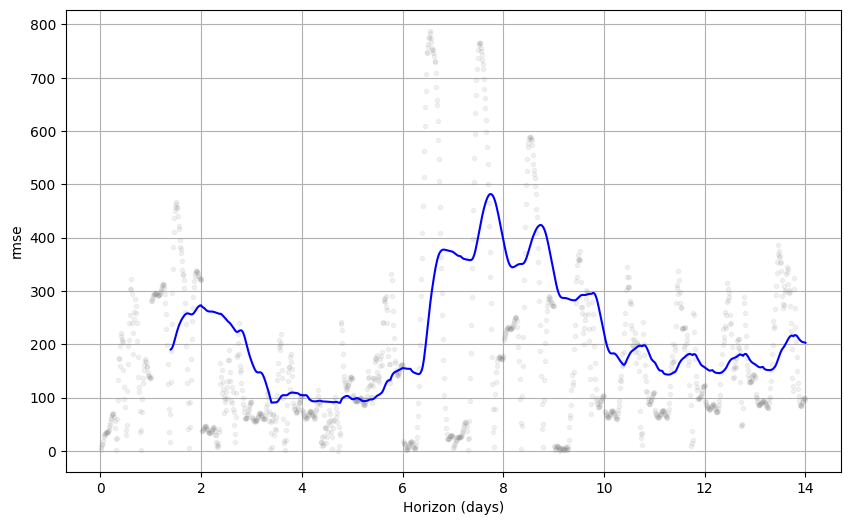

In [12]:
from prophet.diagnostics import cross_validation, performance_metrics

# Define the initial training period, period between each fold, and prediction horizon
initial = '60 days'  # Initial training period
period = '15 days'   # Period between each fold
horizon = '14 days'  # Prediction horizon

# Perform cross-validation
df_cv = cross_validation(prophet_model, initial=initial, period=period, horizon=horizon)

# Evaluate the model's performance
df_p = performance_metrics(df_cv)
print(df_p.head())

# Plot the cross-validation results
from prophet.plot import plot_cross_validation_metric
fig = plot_cross_validation_metric(df_cv, metric='rmse')
plt.show()
